# DL-23f3000839: Milestone 1

Sarthak Jain · 23f3000839

I inspect the four defect categories, save an image-level stratified holdout, then train a small U-Net from scratch for five epochs. Training uses the supplied Q11–Q12 loader, normalization, loss and evaluation definitions. Images stay at 128 × 800.

This notebook contains the actual local MPS run outputs. The ResNet-34 Kaggle attempt remained in the GPU queue, so these results belong to the scratch model. The random encoder has three pooling stages and 487,060 parameters.

The data-audit results below were produced by `src/analyze.py`; the saved JSON and plots are included in the repository. Run the notebook from the project root after downloading the competition data. W&B authentication is external to the notebook.

## Full-dataset audit

The RLE audit records endpoints before clipping. Mask components use 8-connectivity. Pixel statistics compare a class mask with its complement in the same image.

In [ ]:
from pathlib import Path
import json
import pandas as pd

audit = json.loads(Path("reports/milestone-1-data-results.json").read_text())
print(json.dumps(audit, indent=2))

{
  "images": 11393,
  "pairs": 45572,
  "positive_counts": {
    "defect_a": 1081,
    "defect_b": 313,
    "defect_c": 4100,
    "defect_d": 1707
  },
  "clean_images": 5516,
  "q1": 9616,
  "q2": 1198,
  "q3": 0,
  "boundary_rows": 0,
  "max_index": 102400,
  "q5": [
    0.32,
    2.0,
    6.25
  ],
  "cohens_d": {
    "defect_a": 0.3197506786880276,
    "defect_b": 0.5316919738284078,
    "defect_c": 0.3683486414064567,
    "defect_d": -0.04566787302433982
  },
  "q7": [
    1.0,
    0.0
  ],
  "q8": [
    0.64,
    0.999,
    0.9,
    0.7378
  ],
  "empty_pairs": 38371,
  "naive_all_empty": 0.8419863073817256,
  "weighted_all_empty": 0.3,
  "min_component_b": 93,
  "lost_pct_b_50": 0.0,
  "lost_pct_a_200": 15.217052884401548,
  "combinations": {
    "clean": 5516,
    "defect_a": 601,
    "defect_a+defect_b": 23,
    "defect_a+defect_b+defect_c": 8,
    "defect_a+defect_b+defect_d": 11,
    "defect_a+defect_c": 215,
    "defect_a+defect_c+defect_d": 87,
    "defect_a+defect_d": 13

### Class distribution and intensity comparison

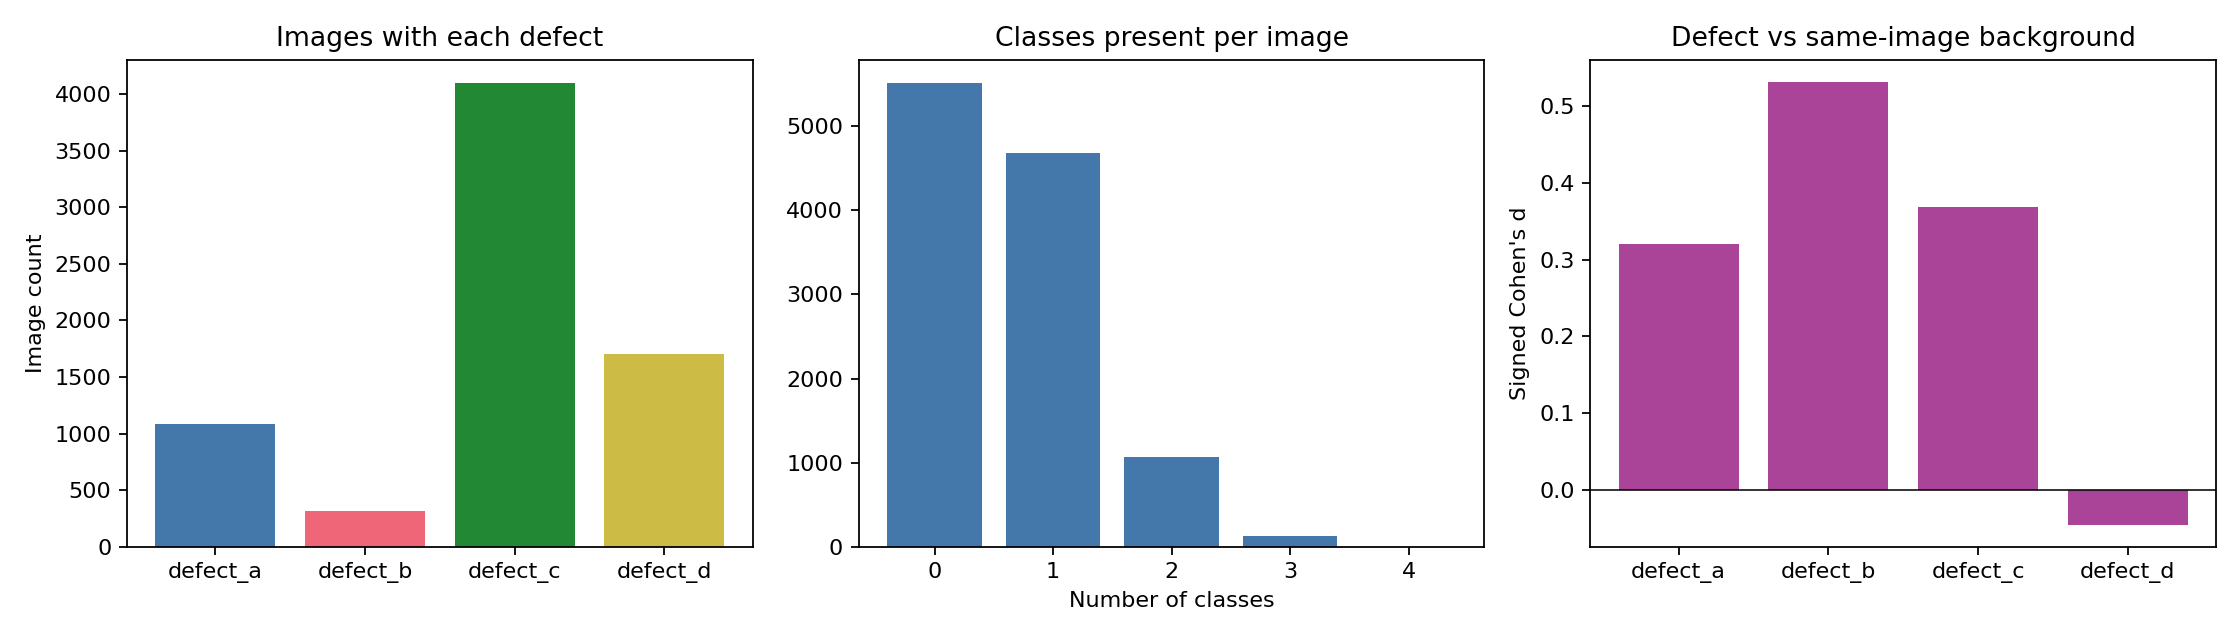

### Native images and decoded masks

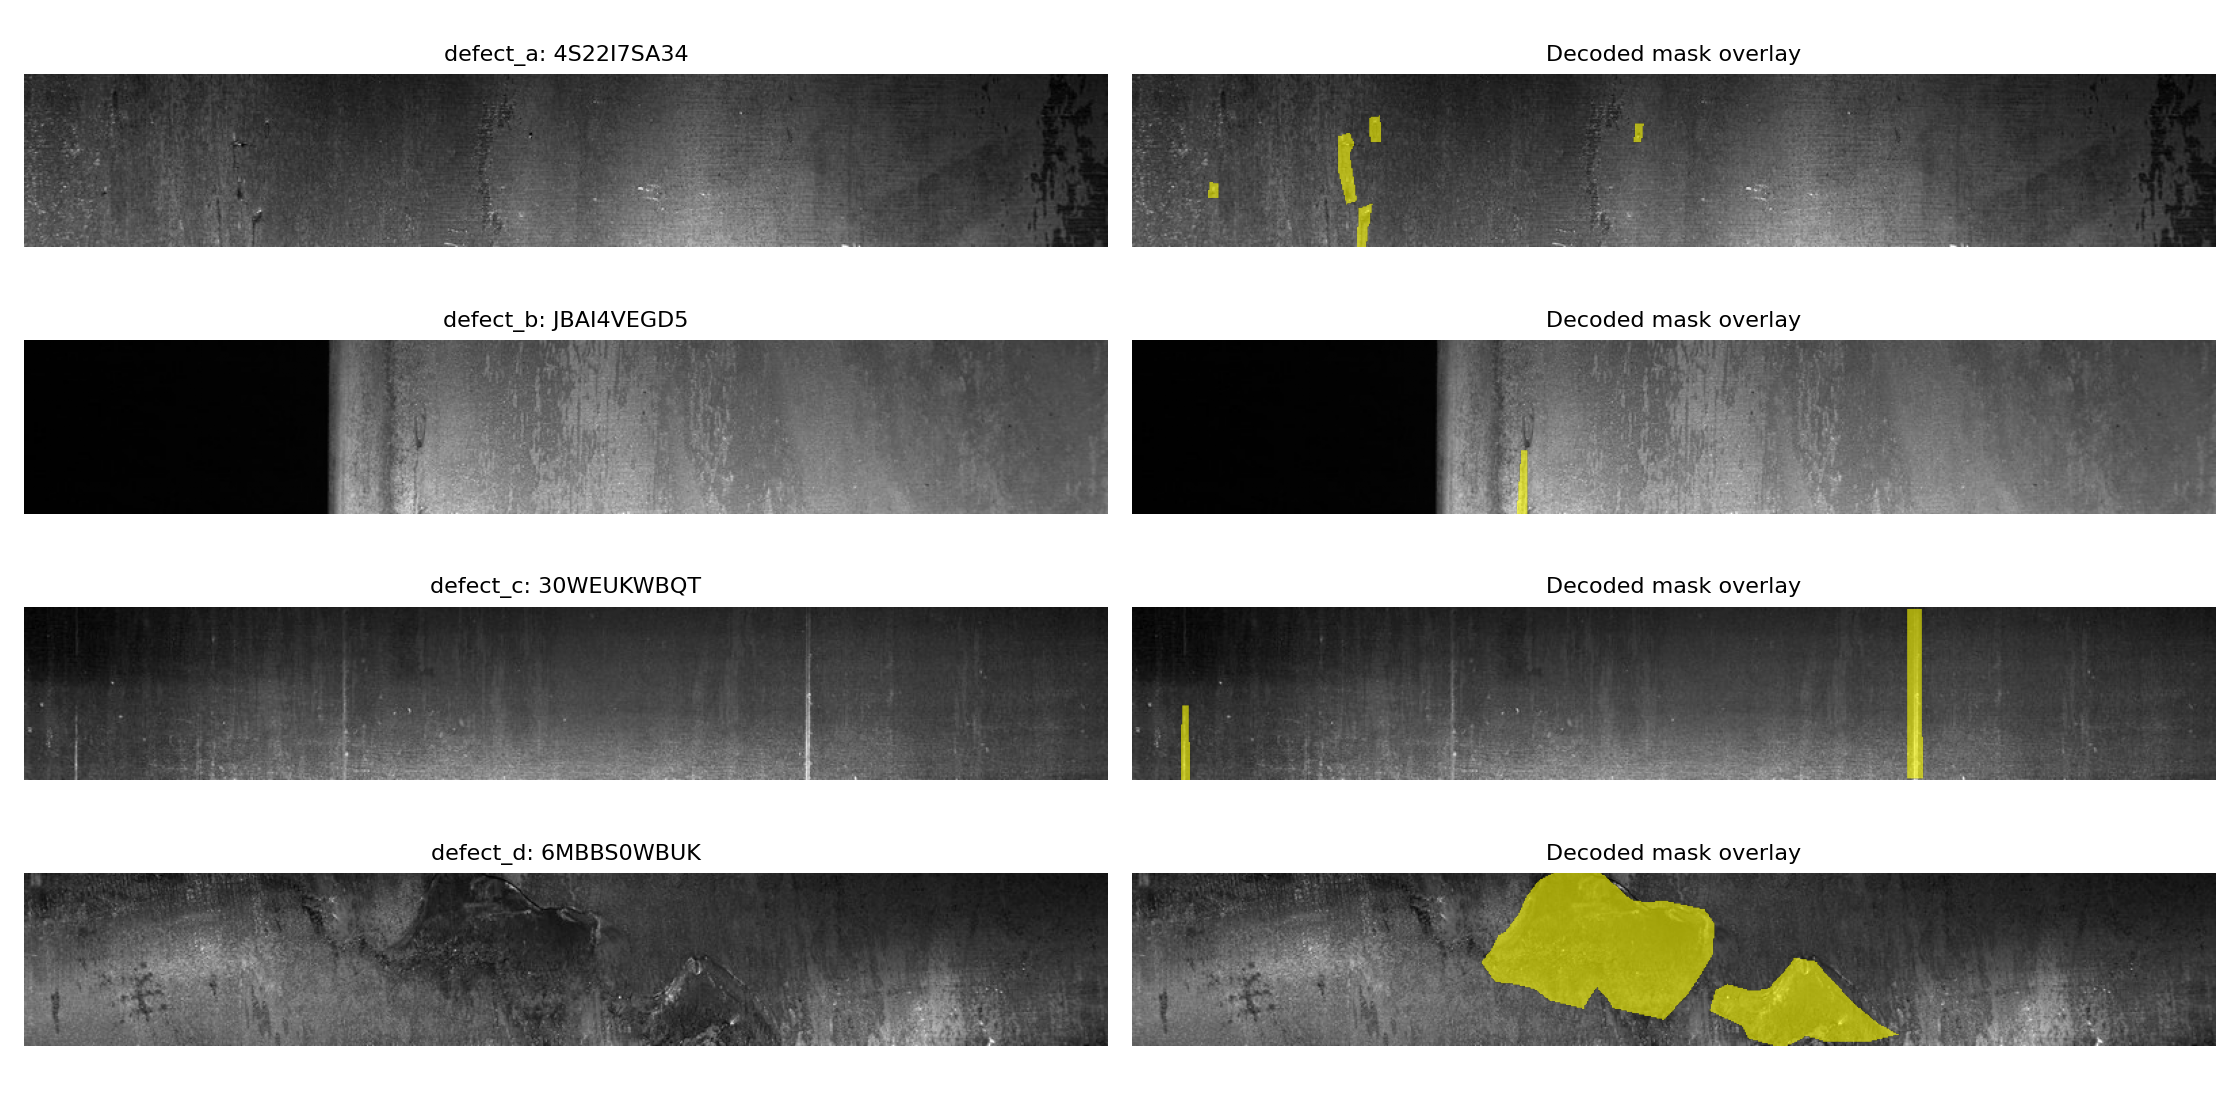

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

from tqdm.auto import tqdm

DATA_ROOT = Path('data/public')  # EDIT for Kaggle or your local environment.
OUTPUT_DIR = Path('runs/scratch')
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
VAL_FRACTION = 0.20
SEED = 42
EPOCHS = 5  # Question 12: use 5–10 epochs.
BATCH_SIZE = 8
ENCODER = "small-unet-scratch"  # Alternative: "efficientnet-b0".
ENCODER_WEIGHTS = None
THRESHOLDS = [0.3, 0.5, 0.7, 0.9]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)

torch.set_num_threads(4)

Device: mps


In [2]:
annotations = pd.read_csv(DATA_ROOT / "train.csv", dtype=str, keep_default_na=False)
required = {"image_id", "defect_type", "mask_rle", "height", "width"}
if not required.issubset(annotations.columns):
    raise ValueError(f"Missing CSV columns: {required - set(annotations.columns)}")
if set(annotations["defect_type"]) != set(CLASSES):
    raise ValueError("Unexpected defect classes")
if annotations.duplicated(["image_id", "defect_type"]).any():
    raise ValueError("Duplicate image–class rows")
if not (annotations.groupby("image_id").size() == len(CLASSES)).all():
    raise ValueError("Every image must have one row for each of the four classes")
if not ((annotations["height"].astype(int) == HEIGHT)
        & (annotations["width"].astype(int) == WIDTH)).all():
    raise ValueError("Expected native height=128 and width=800")

annotations["mask_rle"] = annotations["mask_rle"].str.strip()
rle_table = annotations.pivot(
    index="image_id", columns="defect_type", values="mask_rle"
).reindex(columns=CLASSES).sort_index()
presence = rle_table.ne("")  # Boolean image × class table.


def combination_string(row):
    active_classes = [name for name in CLASSES if row[name]]
    return "+".join(active_classes) if active_classes else "clean"


image_table = presence.copy()
image_table["label_combo"] = presence.apply(combination_string, axis=1)
combination_counts = image_table["label_combo"].value_counts().sort_index()

In [3]:
n_combos = int(combination_counts.size)  # Includes the clean combination.
b_in_val_ideal = round(VAL_FRACTION * int(presence["defect_b"].sum()))  # Round once after allocating 20% of all defect_b positives.
# Record your calculation and final short answer in your own working notes.

In [4]:
if combination_counts.min() < 2:
    rare = combination_counts[combination_counts < 2]
    raise ValueError(f"Singleton combinations need an explicit split policy:\n{rare}")
train_ids, val_ids = train_test_split(
    image_table.index.to_numpy(),
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=image_table["label_combo"].to_numpy(),
)
assert not set(train_ids) & set(val_ids)
assert set(train_ids) | set(val_ids) == set(image_table.index)

split_table = image_table[["label_combo"]].copy()
split_table["partition"] = "train"
split_table.loc[val_ids, "partition"] = "validation"
split_table.to_csv(OUTPUT_DIR / "holdout.csv", index_label="image_id")
print("Train images:", len(train_ids), "Validation images:", len(val_ids))
# Optional: compare class prevalence in each partition. Do not infer the ideal
# Question 11 count solely from the rounded counts in this actual split.

Train images: 9114 Validation images: 2279


In [5]:
def decode_rle(rle):
    flat = np.zeros(HEIGHT * WIDTH, dtype=np.float32)
    if not str(rle).strip():
        return flat.reshape(HEIGHT, WIDTH, order="F")
    tokens = np.asarray(str(rle).split(), dtype=np.int64)
    if len(tokens) % 2:
        raise ValueError("RLE needs start/length pairs")
    starts, lengths = tokens[0::2] - 1, tokens[1::2]
    ends = starts + lengths
    if np.any(starts < 0) or np.any(starts >= flat.size) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length")
    if np.any(starts[1:] < ends[:-1]):
        raise ValueError("Unsorted or overlapping runs in one mask")
    for start, end in zip(starts, np.minimum(ends, flat.size)):
        flat[start:end] = 1.0
    return flat.reshape(HEIGHT, WIDTH, order="F")


class SurfaceDataset(Dataset):
    def __init__(self, image_ids, rle_table, data_root):
        self.image_ids = list(image_ids)
        self.rle_table = rle_table
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        filename = image_id if image_id.endswith(".jpg") else image_id + ".jpg"
        with Image.open(self.data_root / "train" / filename) as handle:
            image = np.asarray(handle.convert("L"), dtype=np.float32) / 255.0
        if image.shape != (HEIGHT, WIDTH):
            raise ValueError(f"Wrong image shape for {image_id}: {image.shape}")
        # Normalize independently per image; train and validation use the same rule.
        image = (image - image.mean()) / max(float(image.std()), 0.05)
        masks = np.stack([decode_rle(self.rle_table.loc[image_id, c]) for c in CLASSES])
        return torch.from_numpy(image[None].copy()), torch.from_numpy(masks.copy())


train_dataset = SurfaceDataset(train_ids, rle_table, DATA_ROOT)
val_dataset = SurfaceDataset(val_ids, rle_table, DATA_ROOT)
# workers=0 works in notebooks and on macOS without multiprocessing setup.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=DEVICE.type == "cuda", generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
image, masks = train_dataset[0]
assert image.shape == (1, HEIGHT, WIDTH)
assert masks.shape == (len(CLASSES), HEIGHT, WIDTH)
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
axes[0].imshow(image[0], cmap="gray")
axes[0].set_title("Training image")
for c, axis in enumerate(axes[1:]):
    axis.imshow(masks[c], cmap="gray", vmin=0, vmax=1)
    axis.set_title(CLASSES[c])
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

<ipython-input-5-8f790a32e650>:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.layers(x)

class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(1, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.bottleneck = ConvBlock(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.dec3 = ConvBlock(128 + 64, 64)
        self.dec2 = ConvBlock(64 + 32, 32)
        self.dec1 = ConvBlock(32 + 16, 16)
        self.head = nn.Conv2d(16, 4, 1)
    def forward(self, x):
        a = self.enc1(x)
        b = self.enc2(self.pool(a))
        c = self.enc3(self.pool(b))
        x = self.bottleneck(self.pool(c))
        for skip, decoder in [(c, self.dec3), (b, self.dec2), (a, self.dec1)]:
            x = nn.functional.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = decoder(torch.cat([x, skip], dim=1))
        return self.head(x)

model = SmallUNet().to(DEVICE)
print("Parameters:", sum(p.numel() for p in model.parameters()))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, targets):
    bce = bce_loss(logits, targets)
    probs = logits.sigmoid()
    intersection = (probs * targets).sum(dim=(-2, -1))
    denominator = probs.sum(dim=(-2, -1)) + targets.sum(dim=(-2, -1))
    soft_dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
    positive = (targets.sum(dim=(-2, -1)) > 0).to(logits.dtype)
    dice_loss = ((1 - soft_dice) * positive).sum() / positive.sum().clamp_min(1)
    return 0.5 * bce + 0.5 * dice_loss


@torch.no_grad()
def validation_loss(model, loader):
    model.eval()
    total, samples = 0.0, 0
    for images, targets in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        loss = segmentation_loss(model(images), targets)
        total += loss.item() * len(images)
        samples += len(images)
    return total / samples

Parameters: 487060


In [7]:
import wandb
# Authenticate with wandb login before running; never put the key in the notebook.
run = wandb.init(entity="23f3000839-iit-madras-foundation", project="23f3000839-t32026", name="m1-small-unet-scratch-seed42", job_type="training", config={"model":"small-unet-scratch", "seed":SEED, "epochs":EPOCHS, "batch_size":BATCH_SIZE, "height":HEIGHT, "width":WIDTH, "pretrained":False, "train_images":len(train_ids), "validation_images":len(val_ids), "loss":"0.5 BCE + 0.5 positive Dice", "augmentation":"none"}, dir=str(OUTPUT_DIR))
history = []
best_val_loss = float("inf")
checkpoint_path = OUTPUT_DIR / "best.pt"
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, samples = 0.0, 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", mininterval=30)
    for images, targets in progress:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = segmentation_loss(model(images), targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(images)
        samples += len(images)
        progress.set_postfix(loss=running_loss / samples)
    val_loss = validation_loss(model, val_loader)
    history.append({"epoch": epoch, "train_loss": running_loss / samples, "val_loss": val_loss})
    print(history[-1], flush=True)
    run.log(history[-1], step=epoch)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)
pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))

{'epoch': 1, 'train_loss': 0.4278523693593259, 'val_loss': 0.4098221574398759}
{'epoch': 2, 'train_loss': 0.3623023717117487, 'val_loss': 0.3552267537168266}
{'epoch': 3, 'train_loss': 0.3437746959140237, 'val_loss': 0.34473704237747527}
{'epoch': 4, 'train_loss': 0.3302037975218884, 'val_loss': 0.32992962740293036}
{'epoch': 5, 'train_loss': 0.31923190129985013, 'val_loss': 0.31386280810430206}
Out[7]: <All keys matched successfully>


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: 23f3000839 (23f3000839-iit-madras-foundation) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 899fn5ea
wandb: Tracking run with wandb version 0.28.0
wandb: Run data is saved locally in /Users/sarthakjain/college/dlgenai-2026t3/local_results/wandb/run-20261018_170742-899fn5ea
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run m1-small-unet-scratch-seed42
wandb:  View project at https://wandb.ai/23f3000839-iit-madras-foundation/23f3000839-t32026
wandb:  View run at https://wandb.ai/23f3000839-iit-madras-foundation/23f3000839-t32026/runs/899fn5ea
Epoch 5/5: 100%|##########| 1140/1140 [03:05<00:00,  6.14it/s, loss=0.319]


In [8]:
@torch.no_grad()
def threshold_sweep(model, loader, thresholds):
    model.eval()
    totals = {tau: dict(pairs=0, positive=0, empty=0, dice_sum=0.0,
                       fg_dice_sum=0.0, fp_fraction_sum=0.0, correct_empty=0)
              for tau in thresholds}
    for images, targets in tqdm(loader, desc="Validation threshold sweep"):
        probs = model(images.to(DEVICE)).sigmoid()
        truth = targets.to(DEVICE) > 0.5
        gt_pixels = truth.sum(dim=(-2, -1))
        positive, empty = gt_pixels > 0, gt_pixels == 0
        for tau in thresholds:
            prediction = probs >= tau  # Raw probabilities; no component/area filtering.
            pred_pixels = prediction.sum(dim=(-2, -1))
            intersection = (prediction & truth).sum(dim=(-2, -1))
            denominator = pred_pixels + gt_pixels
            dice = torch.where(
                denominator == 0, torch.ones_like(denominator, dtype=torch.float32),
                2.0 * intersection / denominator.clamp_min(1),
            )
            total = totals[tau]
            total["pairs"] += truth.shape[0] * truth.shape[1]
            total["positive"] += int(positive.sum().item())
            total["empty"] += int(empty.sum().item())
            total["dice_sum"] += dice.sum().item()
            total["fg_dice_sum"] += dice[positive].sum().item()
            total["fp_fraction_sum"] += (pred_pixels[empty].float() / (HEIGHT * WIDTH)).sum().item()
            total["correct_empty"] += int((empty & (pred_pixels == 0)).sum().item())
    rows = []
    for tau, total in totals.items():
        if not total["positive"] or not total["empty"]:
            raise ValueError("The holdout needs both positive and empty image–class pairs")
        fg = total["fg_dice_sum"] / total["positive"]
        fp_fraction = total["fp_fraction_sum"] / total["empty"]
        empty_accuracy = total["correct_empty"] / total["empty"]
        rows.append({
            "threshold": tau,
            "naive_dice": total["dice_sum"] / total["pairs"],
            "foreground_dice": fg,
            "fp_pixel_fraction": fp_fraction,
            "fp_pair_rate": 1 - empty_accuracy,
            "false_positive_score": 1 - fp_fraction,
            "empty_accuracy": empty_accuracy,
            "assessment_score": 0.70 * fg + 0.20 * (1 - fp_fraction) + 0.10 * empty_accuracy,
            "holdout_empty_pair_fraction": total["empty"] / total["pairs"],
        })
    return pd.DataFrame(rows).sort_values("threshold")


results = threshold_sweep(model, val_loader, THRESHOLDS)
results.to_csv(OUTPUT_DIR / "threshold_sweep.csv", index=False)
print(results.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for metric in ["naive_dice", "foreground_dice", "assessment_score"]:
    axes[0].plot(results["threshold"], results[metric], marker="o", label=metric)
axes[0].set_ylabel("Score")
axes[1].plot(results["threshold"], results["fp_pair_rate"], marker="o")
axes[1].set_ylabel("Empty pairs with any false positive (fraction)")
axes[2].plot(results["threshold"], results["fp_pixel_fraction"], marker="o")
axes[2].set_ylabel("Mean false-positive pixel fraction on empty pairs")
for axis in axes:
    axis.set_xlabel("Decision threshold")
    axis.set_xticks(THRESHOLDS)
    axis.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "threshold_sweep.png", dpi=160)
plt.show()

 threshold  naive_dice  foreground_dice  fp_pixel_fraction  fp_pair_rate  false_positive_score  empty_accuracy  assessment_score  holdout_empty_pair_fraction
       0.3    0.170414         0.442397           0.019723      0.880651              0.980277        0.119349          0.517668                     0.841926
       0.5    0.180604         0.441630           0.017308      0.868404              0.982692        0.131596          0.518839                     0.841926
       0.7    0.213012         0.434293           0.012782      0.828534              0.987218        0.171466          0.518596                     0.841926
       0.9    0.464102         0.364161           0.004243      0.517134              0.995757        0.482866          0.502351                     0.841926


Validation threshold sweep: 100%|##########| 285/285 [00:18<00:00, 15.15it/s]
<ipython-input-8-ecc08659a1de>:68: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [9]:
best = results.loc[results.assessment_score.idxmax()]
run.log({"threshold_results": wandb.Table(dataframe=results)})
run.summary.update({"best_assessment_score":float(best.assessment_score),"selected_threshold":float(best.threshold),"best_val_loss":best_val_loss})
Path(OUTPUT_DIR / "wandb_url.txt").write_text(run.url)
run.finish()

wandb: uploading artifact run-899fn5ea-threshold_results; updating run metadata
wandb: uploading artifact run-899fn5ea-threshold_results
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 4-4, summary
wandb: 
wandb: Run summary:
wandb: best_assessment_score 0.51884
wandb:         best_val_loss 0.31386
wandb:                 epoch 5
wandb:    selected_threshold 0.5
wandb:            train_loss 0.31923
wandb:              val_loss 0.31386
wandb: 
wandb:  View run m1-small-unet-scratch-seed42 at: https://wandb.ai/23f3000839-iit-madras-foundation/23f3000839-t32026/runs/899fn5ea
wandb:  View project at: https://wandb.ai/23f3000839-iit-madras-foundation/23f3000839-t32026
wandb: Synced 5 W&B file(s), 1 media file(s), 2 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./college/dlgenai-2026t3/local_results/wandb/run-20261018_170742-899fn5ea/logs


### Raw threshold sweep on the held-out images

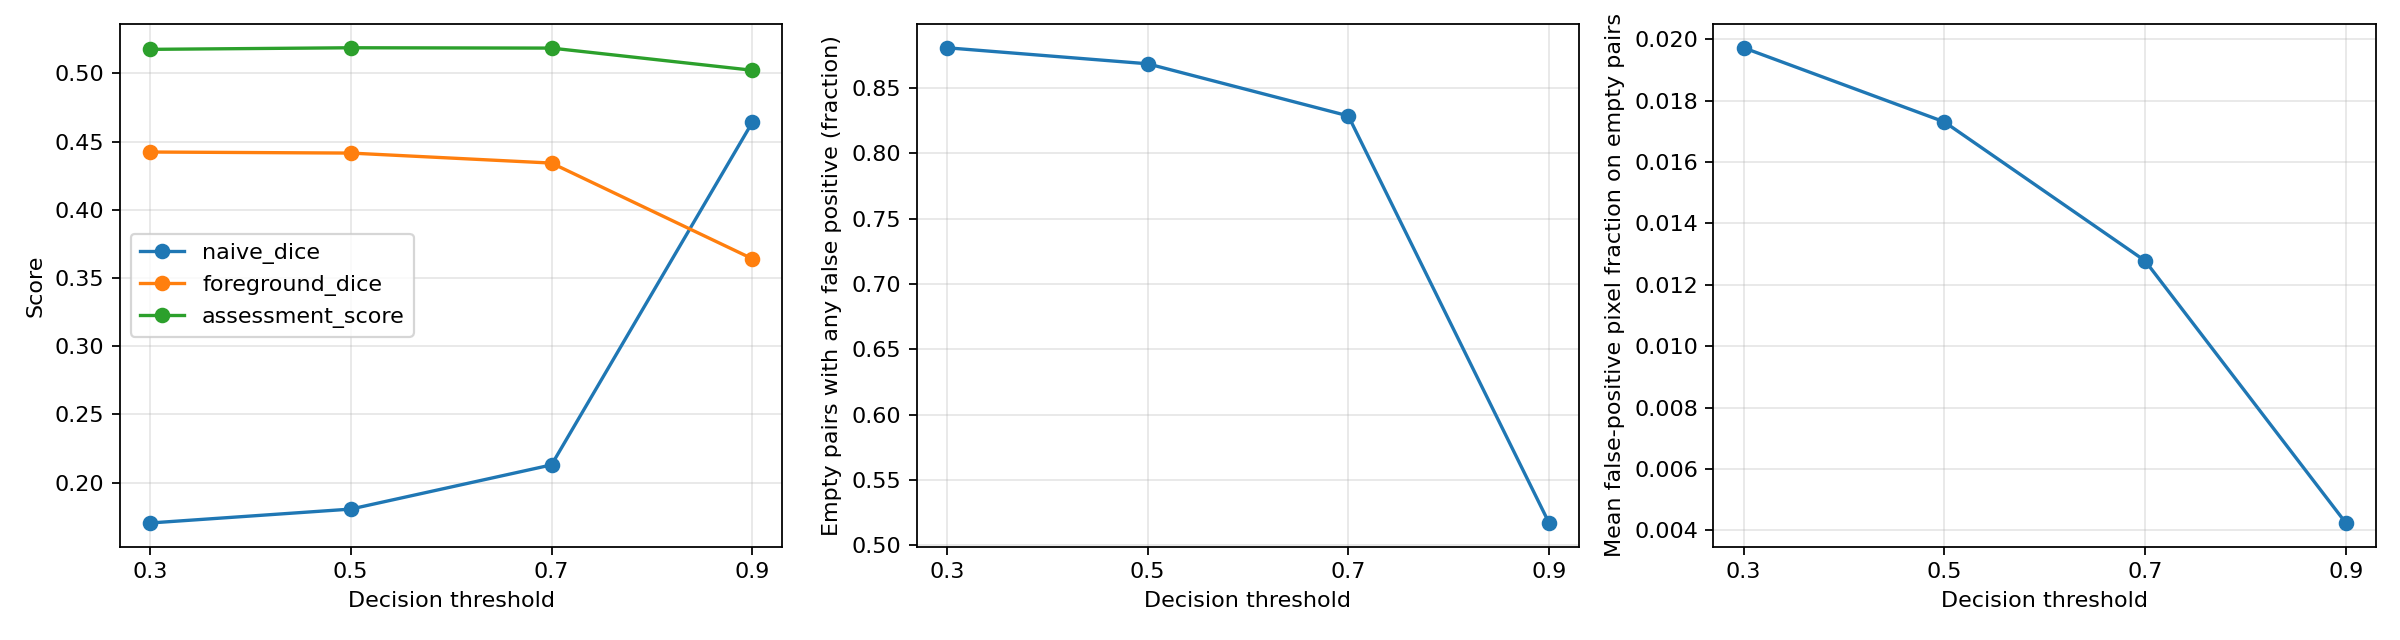

## What I observed

• Trained a small U-Net from scratch (487,060 parameters) for 5 epochs at 128 × 800. The seed-42 combination-stratified split had 9,114 training and 2,279 validation images. Used the epoch-5 checkpoint with the lowest validation loss (0.3139), and no area filtering.
• At thresholds 0.3, 0.5, 0.7 and 0.9, the false-positive pair rates were 88.07%, 86.84%, 82.85% and 51.71%. Foreground Dice was 0.4424, 0.4416, 0.4343 and 0.3642. Higher thresholds reduced noise but also missed more real defect pixels in this run.
• Naive mean Dice peaked at 0.9 (0.4641); the Q8 weighted score peaked at 0.5 (0.5188). Empty pairs made up 84.19% of the holdout, so naive Dice rewarded clearing those masks strongly. The weighted score put 70% weight on positive-pair Dice and therefore preferred 0.5.